# Tensorboard的使用.ipynb

In [ ]:
from pathlib import Path

# 支持从仓库根目录或Notebook所在子目录启动。
def find_project_dir():
    for folder in (Path.cwd(), *Path.cwd().parents):
        if (folder / "Pytorch" / "data").is_dir():
            return folder / "Pytorch"
        if folder.name == "Pytorch" and (folder / "data").is_dir():
            return folder
    raise FileNotFoundError("请从本仓库或其子目录启动Notebook")

PROJECT_DIR = find_project_dir()


**导入Tensorboard**

In [1]:
from torch.utils.tensorboard import SummaryWriter

**SummaryWriter的使用**

In [2]:
help(SummaryWriter)

Help on class SummaryWriter in module torch.utils.tensorboard.writer:

class SummaryWriter(builtins.object)
 |  SummaryWriter(
 |      log_dir=None,
 |      comment='',
 |      purge_step=None,
 |      max_queue=10,
 |      flush_secs=120,
 |      filename_suffix=''
 |  ) -> None
 |
 |  Writes entries directly to event files in the log_dir to be consumed by TensorBoard.
 |
 |  The `SummaryWriter` class provides a high-level API to create an event file
 |  in a given directory and add summaries and events to it. The class updates the
 |  file contents asynchronously. This allows a training program to call methods
 |  to add data to the file directly from the training loop, without slowing down
 |  training.
 |
 |  Methods defined here:
 |
 |  __enter__(self)
 |
 |  __exit__(self, exc_type, exc_val, exc_tb)
 |
 |  __init__(
 |      self,
 |      log_dir=None,
 |      comment='',
 |      purge_step=None,
 |      max_queue=10,
 |      flush_secs=120,
 |      filename_suffix=''
 |  ) -> Non

In [3]:
writer = SummaryWriter(log_dir='logs')#在当前目录下创建logs文件夹，表示日志文件的保存路径

for i in range(100):
    writer.add_scalar('y=2x', 2*i, i) #tag, scalar_value, global_step

writer.close()#关闭writer，释放资源

#tag (str): Data identifier 这条线的名称
#scalar_value (float or string/blobname): Value to save 这一刻的值(y轴)
#global_step (int): Global step value to record 这一刻发生在哪一步(x轴)

**在cmd中输入log路径，并修改port防止服务器多人使用同一端口**

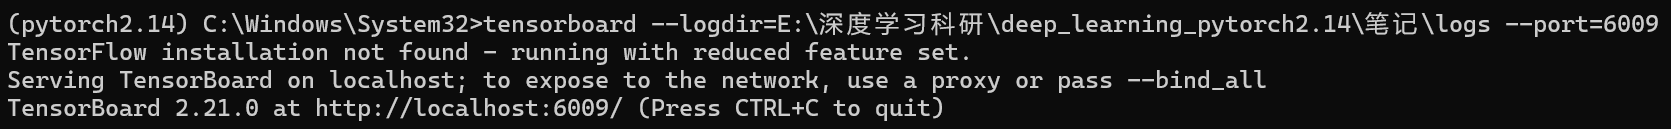

**add_image**

In [ ]:
from PIL import Image

image_path=str(PROJECT_DIR / 'data/train/ants/0013035.jpg')
img=Image.open(image_path)
print(type(img)) #<class 'PIL.JpegImagePlugin.JpegImageFile'>

add_images()的图片类型要求：torch.tensor,np.ndarray

**用Opencv读取文件，获得numpy型图片数据**

In [5]:
import cv2
cv_img=cv2.imread(image_path)
print(type(cv_img)) #<class 'numpy.ndarray'>

<class 'numpy.ndarray'>


**用numpy对PIL图片类型转换**

In [6]:
import numpy as np

img_array=np.array(img)
print(type(img_array)) #<class 'numpy.ndarray'>

<class 'numpy.ndarray'>


In [ ]:
writer = SummaryWriter(log_dir=str(PROJECT_DIR / "code/logs/notebook_images"))
writer.add_image('ant', img_array, 0, dataformats='HWC') #tag, img_tensor, global_step, dataformats(height, width, channels)
print('img_array.shape:', img_array.shape) #HWC

In [ ]:
img_path=str(PROJECT_DIR / 'data/train/ants/5650366_e22b7e1065.jpg')
img=Image.open(img_path)
img_array=np.array(img)
writer.add_image('ant', img_array, 1, dataformats='HWC') #tag, img_tensor, global_step, dataformats(height, width, channels)
#同一个tag下的图片可以在tensorboard中以滑动条的形式查看不同的图片，但本地文件夹中只会保存最后一张图片

#如果想分开保存不同的图片，可以在tag中加上不同的名字，如：bee
img_path=str(PROJECT_DIR / 'data/train/bees/21399619_3e61e5bb6f.jpg')
img=Image.open(img_path)
img_array=np.array(img)
writer.add_image('bee', img_array, 1, dataformats='HWC') #tag, img_tensor, global_step, dataformats(height, width, channels)
writer.close()


从PIL到numpy，需要在add_image中指定dataformats='HWC'，即shape中的每一个数字/维表示的含义

# log文件夹的清理

**每次测试前清空日志,这段代码要放在py最前面**

In [ ]:
# 日志是学习记录，不自动递归删除。需要清理时请手动检查目录后处理。
writer.close()
print("日志已关闭；原有logs目录保留。")


**torch.tensor图片类型的属性和方法**

In [10]:
import torch
print(dir(torch.Tensor)) #查看Tensor类的属性和方法

['H', 'T', '__abs__', '__add__', '__and__', '__annotate_func__', '__array__', '__array_priority__', '__array_wrap__', '__bool__', '__class__', '__complex__', '__contains__', '__cuda_array_interface__', '__deepcopy__', '__delattr__', '__delitem__', '__dict__', '__dir__', '__div__', '__dlpack__', '__dlpack_c_exchange_api__', '__dlpack_device__', '__doc__', '__eq__', '__firstlineno__', '__float__', '__floordiv__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__iadd__', '__iand__', '__idiv__', '__ifloordiv__', '__ilshift__', '__imod__', '__imul__', '__index__', '__init__', '__init_subclass__', '__int__', '__invert__', '__ior__', '__ipow__', '__irshift__', '__isub__', '__iter__', '__itruediv__', '__ixor__', '__le__', '__len__', '__long__', '__lshift__', '__lt__', '__matmul__', '__mod__', '__module__', '__mul__', '__ne__', '__neg__', '__new__', '__nonzero__', '__or__', '__pos__', '__pow__', '__radd__', '__rand__', '__rdiv__', '__reduce__',